In [548]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder , LabelEncoder


In [549]:
df = pd.read_csv("cars_data.csv")
df.head(15)

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,NaN,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0
5,Mazda,2013.0,146888.0,1.3,Diesel,Manual,NaN,3000.0
6,Nissan,2022.0,37733.0,2.5,Petrol,Manual,5,8810.0
7,Nissan,2021.0,7050.0,1.5,Diesel,Automatic,5,10365.0
8,Kia,2022.0,114996.0,2.0,Petrol,Manual,1,4987.0
9,Honda,2022.0,38933.0,3.2,Hybrid,Manual,NaN,21380.0


In [550]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            979 non-null    object 
 1   Year             974 non-null    float64
 2   Mileage          979 non-null    float64
 3   Engine_Size      964 non-null    float64
 4   Fuel_Type        982 non-null    object 
 5   Transmission     962 non-null    object 
 6   Previous_Owners  950 non-null    object 
 7   Price            987 non-null    float64
dtypes: float64(4), object(4)
memory usage: 62.6+ KB


In [551]:
df.describe()

,Year,Mileage,Engine_Size,Price
count,974.000000,979.000000,964.000000,987.000000
mean,2016.320329,104185.955056,2.490560,8473.716312
std,4.050561,56333.931315,0.866082,6301.920977
min,2010.000000,5207.000000,1.000000,3000.000000
25%,2013.000000,54002.500000,1.800000,4068.000000
50%,2016.000000,104853.000000,2.500000,6426.000000
75%,2020.000000,155030.000000,3.200000,10917.000000
max,2023.000000,199812.000000,4.000000,43994.000000


In [552]:
df.duplicated().sum()

np.int64(0)

In [553]:
df.isna().sum()

,0
Brand,21
Year,26
Mileage,21
Engine_Size,36
Fuel_Type,18
Transmission,38
Previous_Owners,50
Price,13


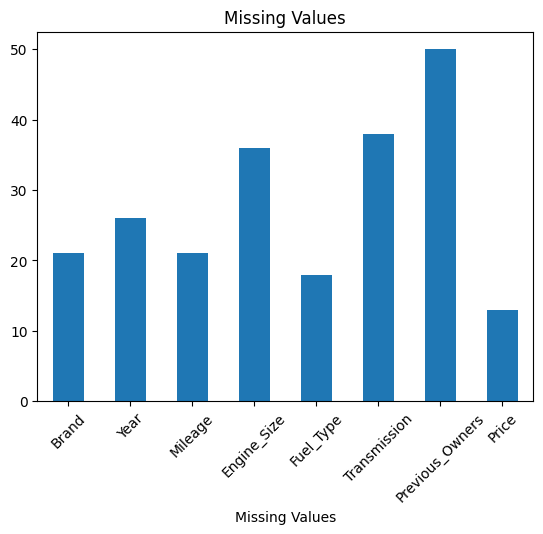

In [554]:
df.isna().sum().plot(kind = "bar")
plt.xlabel("Missing Values")
plt.title("Missing Values")
plt.xticks(rotation=45)
plt.show()

In [555]:
for col in df.select_dtypes("object").columns:
    print(f"{col} : {df[col].unique()}")
    print("*" * 20)

Brand : ['Kia' 'Mercedes' 'Nissan' 'BMW' 'Mazda' 'Honda' 'Hyundai' 'Toyota' nan]
********************
Fuel_Type : ['Electric' 'Petrol' 'Diesel' 'Hybrid' nan]
********************
Transmission : ['Manual' 'Automatic' nan]
********************
Previous_Owners : ['2' '5' '1' nan ' ' '3' '4']
********************


In [556]:
df["Previous_Owners"].value_counts()

,count
Previous_Owners,
5,197
4,193
3,192
2,188
1,179
,1


In [557]:
df["Previous_Owners"] = df["Previous_Owners"].replace(" " , np.nan)
df["Previous_Owners"].value_counts()

,count
Previous_Owners,
5,197
4,193
3,192
2,188
1,179


In [558]:
df.dropna(subset=["Brand"], inplace=True)
df.dropna(subset=["Fuel_Type"], inplace=True)
df.dropna(subset=["Transmission"], inplace=True)
df.dropna(subset=["Previous_Owners"], inplace=True)
df["Previous_Owners"] = df["Previous_Owners"].astype('int')
df.reset_index(drop=True, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 901 entries, 0 to 900
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            901 non-null    object 
 1   Year             897 non-null    float64
 2   Mileage          900 non-null    float64
 3   Engine_Size      876 non-null    float64
 4   Fuel_Type        901 non-null    object 
 5   Transmission     901 non-null    object 
 6   Previous_Owners  901 non-null    int64  
 7   Price            901 non-null    float64
dtypes: float64(4), int64(1), object(3)
memory usage: 56.4+ KB


In [559]:
df.isna().sum()

,0
Brand,0
Year,4
Mileage,1
Engine_Size,25
Fuel_Type,0
Transmission,0
Previous_Owners,0
Price,0


In [560]:
numeric_columns = ['Year', "Mileage", "Engine_Size" ]

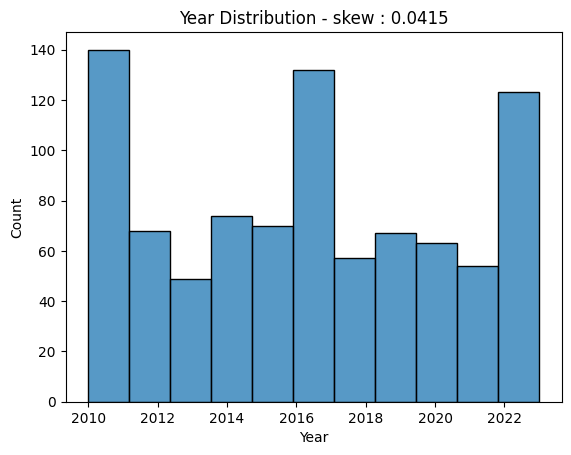

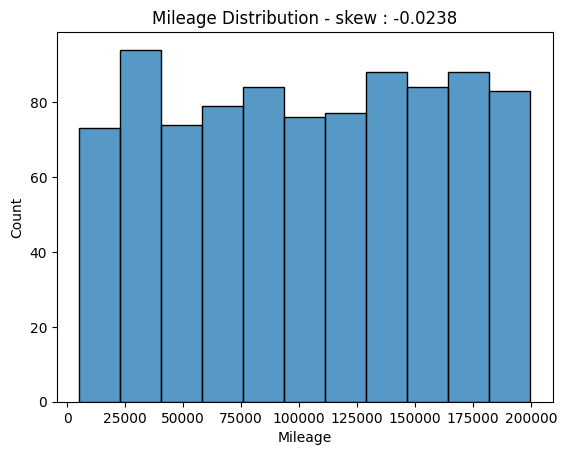

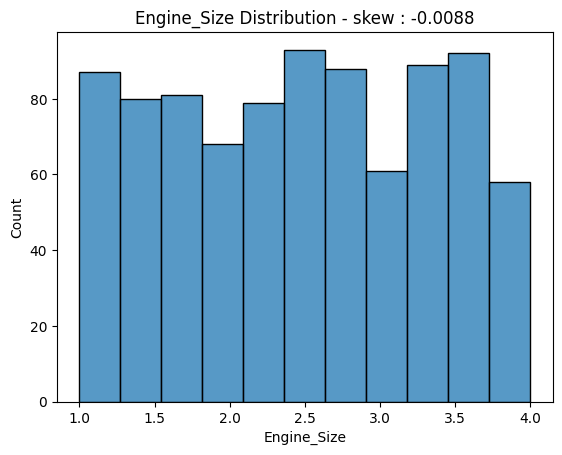

In [561]:
for j , col in enumerate(numeric_columns):
  sns.histplot(df[col] )
  plt.title(f"{col} Distribution - skew : {df[col].skew():.4f}")
  plt.show()

In [562]:
df.isna().sum()

,0
Brand,0
Year,4
Mileage,1
Engine_Size,25
Fuel_Type,0
Transmission,0
Previous_Owners,0
Price,0


In [563]:
corr = df.corr(numeric_only= True)
corr

,Year,Mileage,Engine_Size,Previous_Owners,Price
Year,1.000000,-0.006458,-0.041234,-0.054619,0.525119
Mileage,-0.006458,1.000000,-0.004402,0.015165,-0.374172
Engine_Size,-0.041234,-0.004402,1.000000,-0.013497,0.194888
Previous_Owners,-0.054619,0.015165,-0.013497,1.000000,-0.069582
Price,0.525119,-0.374172,0.194888,-0.069582,1.000000


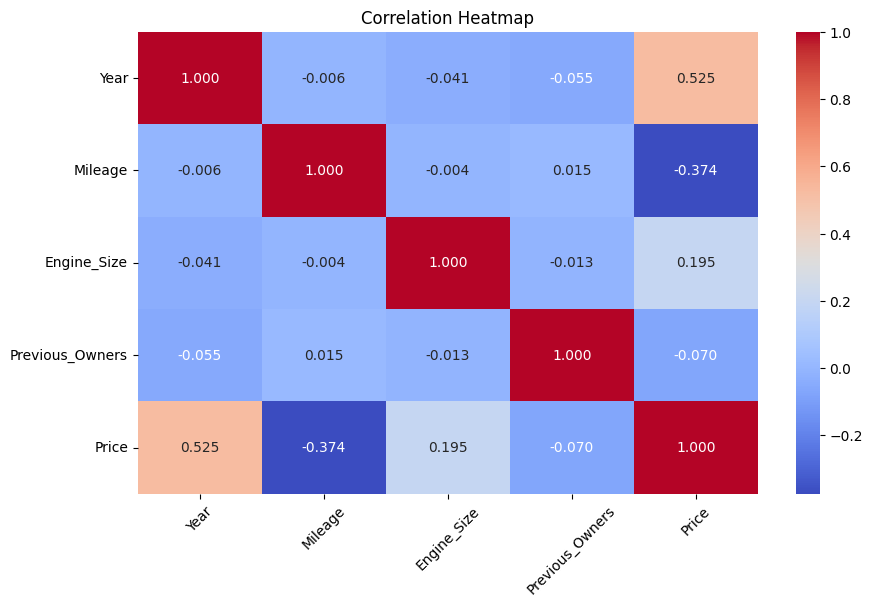

In [564]:
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".3f")
plt.title('Correlation Heatmap')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [565]:
X = df.drop("Price" , axis = 1)
y = df["Price"]

In [566]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state = 42)

In [567]:
impute = SimpleImputer(strategy="mean")
for col in numeric_columns:
  X_train[col] = impute.fit_transform(X_train[[col]])
  X_test[col] = impute.transform(X_test[[col]])

In [568]:
X_train.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners
10,Nissan,2012.0,117573.0,3.7,Petrol,Manual,5
375,BMW,2015.0,106520.0,1.1,Electric,Automatic,5
247,BMW,2010.0,61985.0,2.9,Electric,Automatic,1
388,Mercedes,2021.0,49738.0,3.6,Petrol,Automatic,3
433,Toyota,2021.0,177307.0,1.6,Petrol,Automatic,4


In [569]:
for col in X_train.select_dtypes("object").columns:
    print(f"{col} : {df[col].unique()}")
    print("*" * 20)

Brand : ['Kia' 'Mercedes' 'Nissan' 'BMW' 'Mazda' 'Hyundai' 'Honda' 'Toyota']
********************
Fuel_Type : ['Electric' 'Petrol' 'Diesel' 'Hybrid']
********************
Transmission : ['Manual' 'Automatic']
********************


In [570]:
OHE = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
for col in ['Fuel_Type', 'Brand', "Transmission"]:
  train_encoded = OHE.fit_transform(X_train[[col]])
  test_encoded = OHE.transform(X_test[[col]])

  encoded_cols = OHE.get_feature_names_out([col])
  train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_cols, index=X_train.index)
  test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_cols, index=X_test.index)

  X_train = pd.concat([X_train.drop(columns=[col]), train_encoded_df], axis=1)
  X_test = pd.concat([X_test.drop(columns=[col]), test_encoded_df], axis=1)

X_train.head()

,Year,Mileage,Engine_Size,Previous_Owners,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Brand_BMW,Brand_Honda,Brand_Hyundai,Brand_Kia,Brand_Mazda,Brand_Mercedes,Brand_Nissan,Brand_Toyota,Transmission_Automatic,Transmission_Manual
10,2012.0,117573.0,3.7,5,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
375,2015.0,106520.0,1.1,5,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
247,2010.0,61985.0,2.9,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
388,2021.0,49738.0,3.6,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
433,2021.0,177307.0,1.6,4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


In [571]:
scaler = StandardScaler()
X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)

In [572]:
from sklearn.neighbors import KNeighborsRegressor
KNN = KNeighborsRegressor(n_neighbors= 10, metric= "minkowski" , p = 2)
KNN.fit(X_train_scaler , y_train)

KNeighborsRegressor(n_neighbors=10)

In [573]:
y_pred = KNN.predict(X_test_scaler)

In [574]:
from sklearn.metrics import mean_squared_error , r2_score, mean_absolute_error

In [575]:
print("MSE : " , mean_squared_error(y_test , y_pred))
print("RMSE : " , np.sqrt(mean_squared_error(y_test , y_pred)))
print("MAE : " , mean_absolute_error(y_test , y_pred))
print("R2 : " , r2_score(y_test , y_pred))

MSE :  15206803.723480664
RMSE :  3899.590199428738
MAE :  2791.1618784530388
R2 :  0.5465890685970672


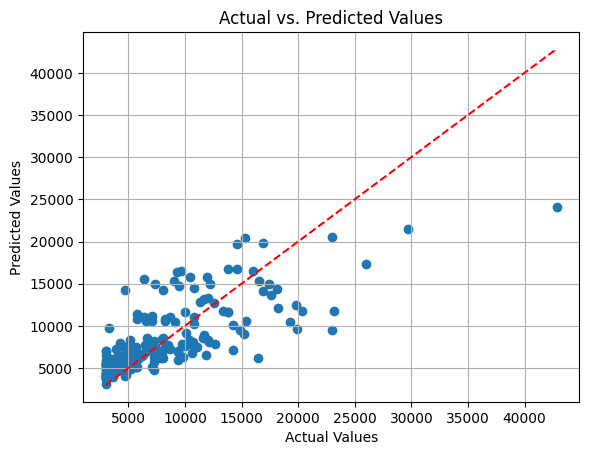

In [576]:
plt.scatter(y_test, y_pred, marker='o')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values')
plt.grid(True)
plt.show()

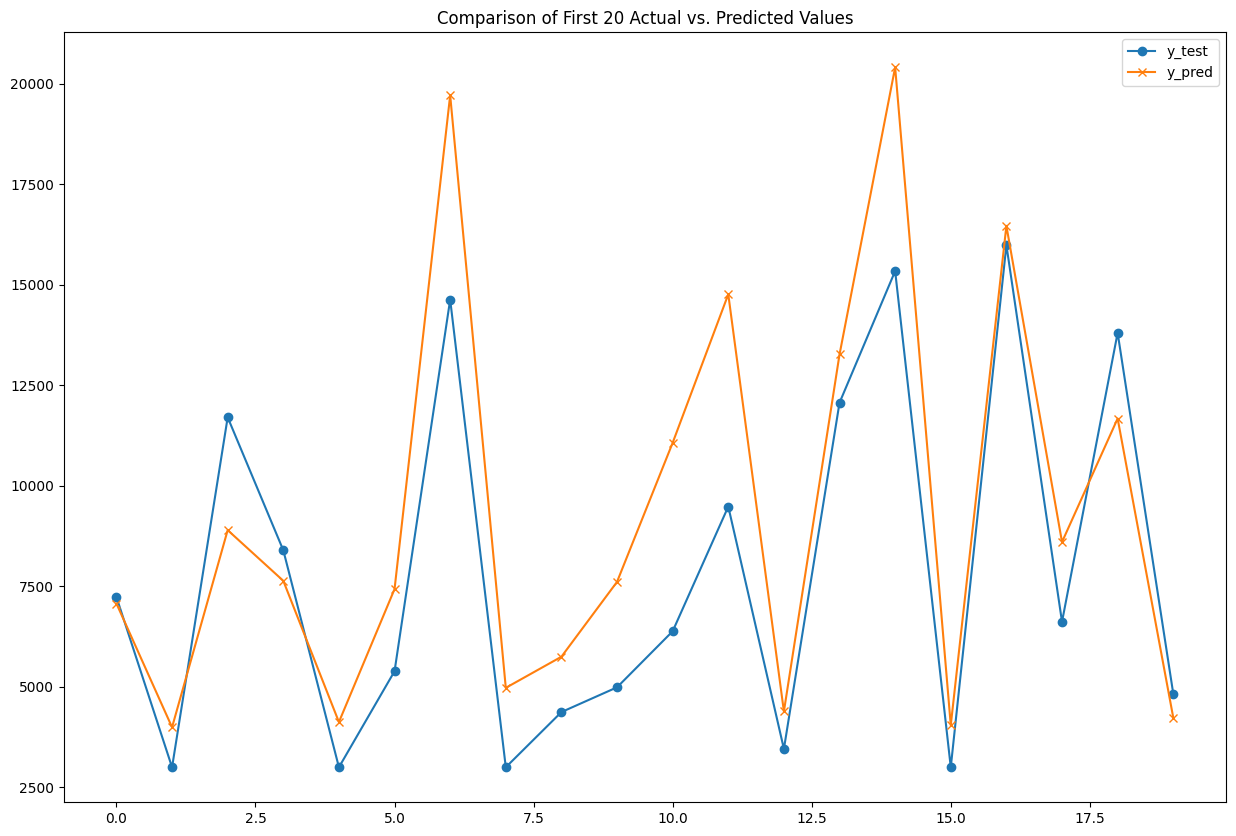

In [577]:
plt.figure(figsize=(15, 10))
plt.plot(y_test.values[:20], label="y_test", marker="o")
plt.plot(y_pred[:20], label="y_pred", marker="x")
plt.legend()
plt.title("Comparison of First 20 Actual vs. Predicted Values")
plt.show()